# What minute sampling does to a movement measure

Md Forhadul Islam, London

This is my independent Dota 2 adaptation of the approach of Fazilat Hojaji,
Robert E. McIlroy, Antoine Dupuy, Gianpaolo Pedroni, Adam J. Toth and Mark J. Campbell.
Their original League of Legends paper is https://doi.org/10.1016/j.chbr.2025.100718.
It is not an exact reproduction of their numerical results. The Betty dataset is
published by wolframko using Valve replays and STRATZ data. Sources, licences and
the literature tracker are recorded in the project documentation.

I explain each step before the code and interpret the output afterwards. All
displayed experimental results come from saved calculations. Reading them does
not train a new model or choose an approach using the final test outcomes.


## Find the saved study

A path tells Python where a file lives. JSON stores labelled evidence. A DataFrame is a table with named columns. This setup reads existing results; it cannot change trained weights or the test partition.

In [1]:
from pathlib import Path  # Represent folders consistently on Windows and other systems.
import sys  # Make the shared project modules available to this notebook.
import json  # Read saved evidence with its original field names.
import pandas as pd  # Display numerical records as labelled tables.
from IPython.display import display, Image, Markdown  # Show readable tables, figures and notes.
ROOT = Path.cwd().resolve()  # Begin from the notebook execution folder.
if ROOT.name == "notebooks":  # Jupyter normally starts within the notebook folder.
    ROOT = ROOT.parent  # Move up once to reach the shared project directory.
assert (ROOT / "src").is_dir(), "Open this notebook from the project or notebooks folder."
sys.path.insert(0, str(ROOT / "src"))  # Import the same scientific code used by terminal runs.
def evidence(filename):  # Keep evidence loading consistent across the notebook.
    return json.loads((ROOT / "outputs/results" / filename).read_text(encoding="utf-8"))  # Decode one saved result.
summary = evidence("D_summary.json")  # Read the completed study without recomputing final predictions.


## Why revisit movement resolution?

The original paper identifies position sampling as a limitation. I study a related measurement issue in Dota 2 using development matches only. Summing distances between approximately one second positions gives an operational sampled path. Joining only minute endpoints omits bends. Neither measurement is continuous ground truth or a direct measure of tactical quality.

In [2]:
movement = summary["movement"]  # Read the completed development measurement experiment.
display(pd.DataFrame(movement["summaries"]))  # Show one match level summary per sampling offset.
print("Native sampling:", movement["native_sampling"])  # State the event anchored timing approximation.
print("Interpretation:", movement["interpretation"])  # Keep measurement scope beside the results.

,offset_seconds,matches,median_retained_fraction,retained_fraction_iqr,median_95_match_bootstrap_interval,matched_intervals
0,0,1374,0.279039,"[0.216291, 0.341397]","[0.272402, 0.283689]",9436
1,15,1337,0.266380,"[0.203041, 0.335025]","[0.259461, 0.273351]",9455
2,30,1330,0.262047,"[0.20183, 0.319737]","[0.25574, 0.267124]",9327
3,45,1371,0.260765,"[0.204325, 0.326632]","[0.254952, 0.266482]",9602


Native sampling: approximately one second with preceding combat event match clock estimates
Interpretation: Operational sampled path displacement on matched continuous segments, not true walking distance or causal influence on winning


The retained fraction is coarse endpoint displacement divided by the native sampled path over the same segment endpoints. The triangle inequality already implies that endpoint chords cannot exceed the corresponding path. The empirical question is the conditional magnitude and its sensitivity to sampling offset.

## Why exclude deaths, gaps and implausible jumps?

A line drawn across a teleport or death can be a fictitious walking distance. The implementation splits at those boundaries, rejects timing gaps and uses a documented speed rule. It never compares unmatched native and coarse endpoints. These rules also remove genuine rapid movement and reduce coverage.

window_seconds                       [0, 1200]
coarse_interval_seconds                     60
offsets_seconds                [0, 15, 30, 45]
speed_multiplier                          1.75
jump_slack_coordinate_units                 64
max_gap_seconds                            1.2
unique_development_matches                6667
dtype: object

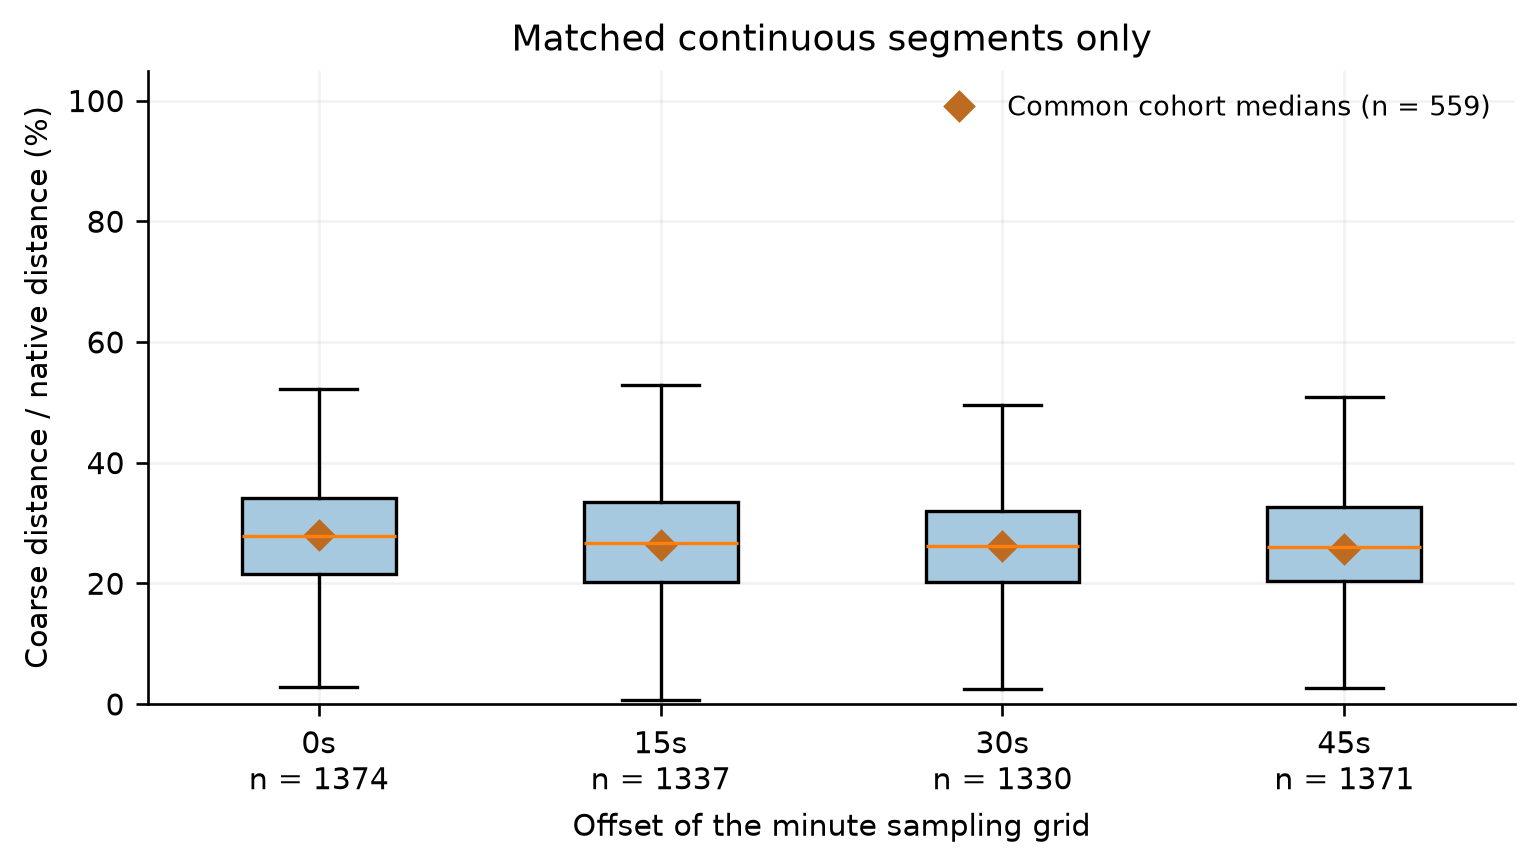

0     0.279641
15    0.263483
30    0.262853
45    0.256280
Name: Median retained fraction on common matches, dtype: float64

Matches supporting every offset: 559


In [3]:
display(pd.Series({key: movement[key] for key in ["window_seconds", "coarse_interval_seconds", "offsets_seconds", "speed_multiplier", "jump_slack_coordinate_units", "max_gap_seconds", "unique_development_matches"]}))  # Show the actual operational rules.
display(Image(filename=str(ROOT / "outputs/figures/D_movement.png")))  # Show distributions rather than only a pooled mean.
display(pd.Series(movement["common_offset_medians"], name="Median retained fraction on common matches"))  # Compare grid offsets while holding matches fixed.
print("Matches supporting every offset:", movement["common_offset_matches"])  # Disclose the restricted common cohort.

Only a subset supplies continuous matched minute segments. Results describe that subset and cannot be extrapolated to every player minute or every match. Coordinate units are not claimed to be metres. Offset comparisons are correlated observations, not independent replications.

## Does this prove movement changes winning KPIs?

No. This experiment measures sampling distortion. Movement was not added to the prediction features, so it does not establish a change in predictive accuracy or KPI ranking. Such a claim would need a new prospectively designed experiment and an untouched evaluation set.

In [4]:
for limitation in movement["limits"]:  # Present all saved qualifications without silently dropping inconvenient ones.
    print(limitation)  # Keep the implementation's own warnings visible to a beginner.

Death and gaps split segments
The speed based jump rule may exclude genuine rapid movement and miss some ability movement
Native sampling is not continuous ground truth
Event anchored clocks have finite sampling resolution
No claim about the magnitude in League of Legends
Offsets are correlated within matches
Only training and validation matches active at the window end; no final test outcomes used


The result supports careful measurement design. It does not reproduce the magnitude of the LoL paper's movement results, identify causal winning behaviour or resolve the original authors' full spatial analysis.

## Read the shared implementation line by line

The source below is the actual function used by the pipeline, including comments explaining what each operation does and why. `inspect` reads Python source; it does not call the function or refit a model. A function is a named sequence of reusable steps; a class groups a model's state and prediction methods. Read the comments alongside the preceding explanation, then open the source file to explore further. The frozen result record retains the original implementation fingerprints; later documentation changes do not replace that historical record.

In [5]:
import inspect  # Read implementation text without running a scientific experiment.
from IPython.display import Code  # Render Python source with readable syntax highlighting.
import dota_movement  # Access the same shared module used by the terminal pipeline.
display(Code(inspect.getsource(dota_movement.trajectory_pairs), language='python'))  # Show the commented implementation without calling it.

def trajectory_pairs(group, speed_multiplier=1.75):
    """Compare coarse and native paths over identical endpoints per segment.

    Sampling at a minute grid uses the most recent preceding observation, not
    a future value. Repeating grid offsets measures phase sensitivity.
    """
    group = group.sort_values("game_time").drop_duplicates("game_time")  # Establish ordered unique observations within one player and match.
    t = group.game_time.to_numpy()  # Extract the observed seconds.
    x, y = group.x.to_numpy(), group.y.to_numpy()  # Extract recorded positions in map coordinate units.
    alive = group.is_alive.to_numpy(dtype=bool)  # Do not connect living movement through death and respawn.
    speed = group.move_speed.to_numpy(dtype=float)  # Use reported movement speed to flag unusually large steps.
    dt = np.diff(t, prepend=np.nan)  # Measure elapsed time since the preceding observation.
    distance = np.hypot(np.diff(x, prepend=np.nan), np.diff(y, prepend=np.nan))  # Calculate straight line displacement between successive sampled positions.
    previous_alive = np.r_[False, alive[:-1]]  # Mark whether the preceding record was alive.
    previous_speed = np.r_[speed[0], speed[:-1]]  # Use both endpoint speeds when allowing a step.
    valid = (dt > 0) & (dt <= 1.2) & alive & previous_alive & np.isfinite(distance) & (distance <= np.maximum(speed, previous_speed) * speed_multiplier * dt + 64)  # Exclude gaps, dead intervals and implausibly large local steps under the stated operational rule.
    segments = np.cumsum(~valid)  # Start a new path segment whenever we cannot justify connecting two points.
    output = []  # Collect matched comparisons for the four minute grid phases.
    for offset in [0, 15, 30, 45]:  # Avoid conclusions depending on a single arbitrary minute boundary.
        native_total, coarse_total, intervals = 0.0, 0.0, 0  # Accumulate only intervals with matched endpoints.
        targets = np.arange(offset, 1200.001, 60.0)  # Define a minute spaced grid within the fixed observation window.
        chosen = np.searchsorted(t, targets, side="right") - 1  # Choose preceding observations rather than future ones.
        eligible = chosen >= 0  # Remove targets before the first observed point.
        chosen, targets = chosen[eligible], targets[eligible]  # Keep matching arrays for the remaining targets.
        eligible = (targets - t[chosen] <= 1.2) & alive[chosen]  # Reject stale and dead observations on the grid.
        chosen = chosen[eligible]  # Retain the valid coarse observation indices.
        cumulative = np.cumsum(np.where(valid, distance, 0))  # Sum native displacements within justified segments.
        for start, end in zip(chosen[:-1], chosen[1:]):  # Compare consecutive eligible coarse samples.
            if segments[start] != segments[end]:  # Never draw a coarse line across a death, gap or jump boundary.
                continue  # Discard unmatched discontinuous intervals from both methods.
            native_total += cumulative[end] - cumulative[start]  # Follow all intervening native samples between these exact endpoints.
            coarse_total += float(np.hypot(x[end] - x[start], y[end] - y[start]))  # Draw the straight coarse line between the same endpoints.
            intervals += 1  # Record the amount of valid comparison support.
        output.append({"offset_seconds": offset, "native_distance": native_total, "coarse_distance": coarse_total, "matched_intervals": intervals})  # Return paired totals rather than incomparable whole path lengths.
    return output, int((~valid).sum()), len(group)  # Provide exclusion diagnostics alongside the comparisons.